## M1
- x, y, z는 모두 최소 0mm보다는 커야한다.
- price의 평균이 중앙값보다 크다. 이는 상대적으로 높은 가격을 가진 데이터가 평균을 높였으며, 데이터의 분포가 오른쪽으로 치우쳐 있을 가능성이 있다는 의미이다.

In [17]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"

df = sns.load_dataset("diamonds")
print(df.shape)
df.head(5)

(53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [23]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


## M2

In [59]:
print(f"x 값이 0인 행의 개수: {len(df.loc[df["x"] == 0, ["x"]])}개")
print(f"y 값이 0인 행의 개수: {len(df.loc[df["y"] == 0, ["y"]])}개")
print(f"z 값이 0인 행의 개수: {len(df.loc[df["z"] == 0, ["z"]])}개")

zero_rows = df.loc[(df["x"] == 0) | (df["y"] == 0) | (df["z"] == 0), ["x", "y", "z"]]
print(f"x, y, z 중 하나라도 0인 행의 개수: {len(zero_rows)}개")
zero_rows

x 값이 0인 행의 개수: 8개
y 값이 0인 행의 개수: 7개
z 값이 0인 행의 개수: 20개
x, y, z 중 하나라도 0인 행의 개수: 20개


,x,y,z
2207,6.55,6.48,0.0
2314,6.66,6.60,0.0
4791,6.50,6.47,0.0
5471,6.50,6.47,0.0
10167,7.15,7.04,0.0
11182,0.00,6.62,0.0
11963,0.00,0.00,0.0
13601,6.88,6.83,0.0
15951,0.00,0.00,0.0
24394,8.49,8.45,0.0


In [61]:
# y 나 z 가 20mm 를 넘는 행
df.loc[(df["y"] > 20) | (df["z"] > 20)]

,carat,cut,color,clarity,depth,table,price,x,y,z
24067,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48410,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49189,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [69]:
before = len(df)
clean = df[~(df["x"] == 0) & ~(df["y"] == 0) & ~(df["z"] == 0) & (df["y"] <= 20) & (df["z"] <= 20)].copy()
print(before, "=>", len(clean))

53940 => 53917


## M3
- carat이 price와 상관계수 값이 가장 높기 때문에 가격 예측에 쓸 특성으로 고른다.

Text(0.5, 0, '가격')

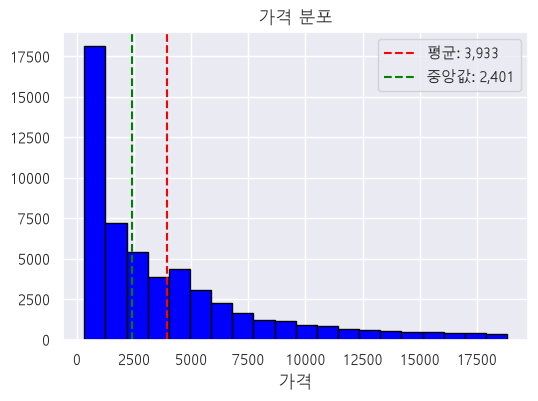

In [ ]:
import platform
import matplotlib.pyplot as plt

os_name = platform.system()

if os_name == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif os_name == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"

mean_price = df["price"].mean()
median_price = df["price"].median()

fig, ax = plt.subplots(figsize=(6,4)) # 그래프 영역 생성
ax.hist(df["price"], bins=20, color="blue", edgecolor="black") # 히스토그램
ax.axvline(mean_price, color="red", linestyle="--", label=f"평균: {mean_price:,.0f}") # 평균 표시
ax.axvline(median_price, color="green", linestyle="--", label=f"중앙값: {median_price:,.0f}") # 중앙값 표시
ax.legend() # 범례
ax.set_title("가격 분포") # 그래프 제목 설정
ax.set_xlabel("가격") # x축 이름 설정

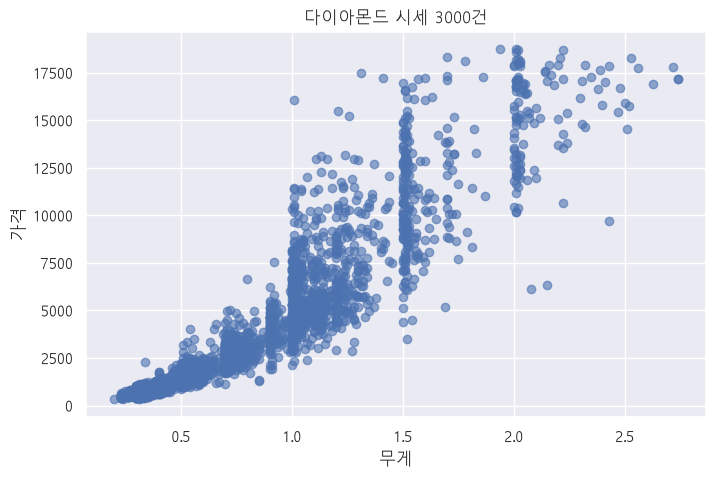

price    1.000000
carat    0.924219
y        0.888143
x        0.886949
z        0.880848
table    0.171482
depth   -0.044792
Name: price, dtype: float64


In [ ]:
sample = clean.sample(3000, random_state=42)

# 산점도 차트
# 캔버스 생성
plt.figure(figsize=(8,5))
# 산점도 차트
plt.scatter(sample["carat"], sample["price"], alpha=0.6)
# 타이틀과 x, y 레이블
plt.title("다이아몬드 시세 3000건")
plt.xlabel("무게")
plt.ylabel("가격")
plt.show()

sample_num = sample.select_dtypes("number")
corr = sample_num.corr()["price"] # price와 각 컬럼의 상관계수 계산
print(corr.sort_values(ascending=False)) # 상관계수가 큰 순서대로 정렬